# **`Predictive Modelling of Glioma Using Machine Learning`**



---


---


Blesson Puthenparambil Koshy

School of Computing, Engineering & Intelligent Systems,

Ulster University, Derry/Londonderry campus

Northern Ireland

Puthenparambil_Koshy-B@ulster.ac.uk


---



---




In [58]:
# Import necessary libraries for Google authentication and PyDrive
from pydrive.auth import GoogleAuth
from pydrive.drive import GoogleDrive
from google.colab import auth
from oauth2client.client import GoogleCredentials

# Authenticate the Google Colab user to access Google services
auth.authenticate_user()

# Initialize GoogleAuth, which handles the Google OAuth flow
gauth = GoogleAuth()

# Set the credentials for PyDrive using the credentials obtained from the authentication
gauth.credentials = GoogleCredentials.get_application_default()

# Create a GoogleDrive object to interact with Google Drive using the authenticated user's credentials
drive = GoogleDrive(gauth)

In [59]:
# Use PyDrive to access a specific file by its ID and download it as a local file named 'Glioma_data.csv'
drive.CreateFile({'id': '1MXeKADAE42Oy8wZuQnHj8WIoLdMHjVwr'}).GetContentFile('Glioma_data.csv')

In [60]:
# Import required libraries for data manipulation and analysis
import pandas as pd
import numpy as np

# Import XGBoost for gradient boosting machine learning model
import xgboost as xgb

# Import visualization libraries to create charts and plots
import matplotlib.pyplot as plt
import seaborn as sns

# Import machine learning metrics to evaluate model performance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, mean_absolute_error
)

# Import utility for splitting training and testing datasets
from sklearn.model_selection import train_test_split

# Import various machine learning algorithms
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

# Import Keras modules for constructing neural networks
from keras.models import Sequential
from keras.layers import Dense

# Import SMOTE for handling class imbalance by oversampling the minority class
from imblearn.over_sampling import SMOTE

# Import warnings library to suppress warnings
import warnings
warnings.filterwarnings("ignore")

# Set a seed for reproducibility
seed = 1152
np.random.seed(seed)


In [61]:
# Load the dataset from a CSV file into a pandas DataFrame
Glioma_df = pd.read_csv('/content/Glioma_data.csv')

# Create a copy of the DataFrame to preserve the original data during manipulation
Glioma_dfCopy = Glioma_df.copy()


In [62]:
def read_main():
    glioma_df = Glioma_df.copy()

    # Remove rows with missing values to ensure data quality
    glioma_df.dropna(inplace=True)

    # Reorder columns: move the first column to the end for better accessibility or analysis
    glioma_df = glioma_df.iloc[:, [*range(1, glioma_df.shape[1]), 0]]

    # Remove duplicate rows to maintain unique data entries
    df_unique = glioma_df.drop_duplicates()

    # Calculate and print the count of unique values in the 'Grade' column
    class_counts = df_unique['Grade'].value_counts()
    print("Class counts for the 'Grade' column:")
    print(class_counts)

    # Return the processed DataFrame
    return df_unique




---



---



---



# **Exploratory Data Analysis (EDA)**

In [63]:
# Call the read_main function to process and clean the Glioma dataset, and store the result in glioma_df
glioma_df = read_main()

Class counts for the 'Grade' column:
Grade
0    486
1    352
Name: count, dtype: int64


In [64]:
# Map numerical codes to categorical labels in the 'Gender' column for better readability and analysis
glioma_df['Gender'] = glioma_df['Gender'].map({0: 'Male', 1: 'Female'})

# Map numerical codes to categorical labels in the 'Grade' column to represent low-grade glioma (LGG) and glioblastoma (GBM)
glioma_df['Grade'] = glioma_df['Grade'].map({0: 'LGG', 1: 'GBM'})


In [65]:
# Calculate and print descriptive statistics for numerical features in the DataFrame
numerical_stats = glioma_df.describe()
print("Descriptive Statistics for Numerical Features:")
print(numerical_stats)


Descriptive Statistics for Numerical Features:
       Age_at_diagnosis        Race        IDH1        TP53        ATRX  \
count        838.000000  838.000000  838.000000  838.000000  838.000000   
mean          50.954212    0.107399    0.480907    0.414081    0.257757   
std           15.702264    0.369594    0.499934    0.492857    0.437660   
min           14.420000    0.000000    0.000000    0.000000    0.000000   
25%           38.070000    0.000000    0.000000    0.000000    0.000000   
50%           51.555000    0.000000    0.000000    0.000000    0.000000   
75%           62.815000    0.000000    1.000000    1.000000    1.000000   
max           89.290000    3.000000    1.000000    1.000000    1.000000   

             PTEN        EGFR         CIC       MUC16      PIK3CA  ...  \
count  838.000000  838.000000  838.000000  838.000000  838.000000  ...   
mean     0.168258    0.133652    0.132458    0.116945    0.087112  ...   
std      0.374318    0.340481    0.339191    0.321547  

In [66]:
# Calculate and print the frequency of each category in the 'Gender' column
gender_counts = glioma_df['Gender'].value_counts()
print("\nFrequency Counts for Gender:")
print(gender_counts)



Frequency Counts for Gender:
Gender
Male      487
Female    351
Name: count, dtype: int64


In [67]:
# Calculate and print the frequency of each category in the 'Race' column
race_counts = glioma_df['Race'].value_counts()
print("\nFrequency Counts for Race:")
print(race_counts)



Frequency Counts for Race:
Race
0    764
1     59
2     14
3      1
Name: count, dtype: int64


In [68]:
# Calculate and print the frequency of each category in the 'Grade' column
grade_counts = glioma_df['Grade'].value_counts()
print("\nFrequency Counts for Grade:")
print(grade_counts)


Frequency Counts for Grade:
Grade
LGG    486
GBM    352
Name: count, dtype: int64


### **Distribution Analysis**

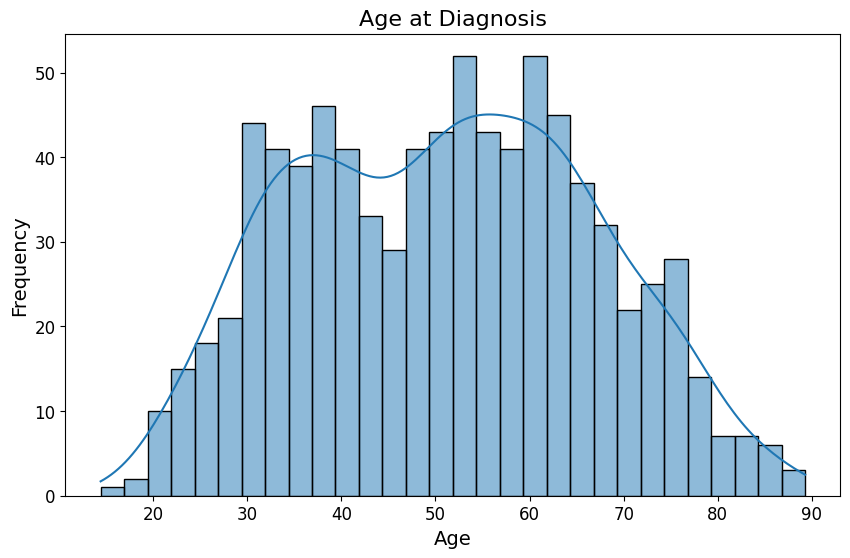

In [69]:
def Histogram_Age(Age):
    # Set up the figure size for the histogram
    plt.figure(figsize=(10, 6))
    sns.histplot(Age, kde=True, bins=30)

    # Set the title and labels for the histogram
    plt.title('Age at Diagnosis')
    plt.xlabel('Age')
    plt.ylabel('Frequency')
    plt.show()

# Call the Histogram_Age function to plot the histogram for 'Age_at_diagnosis' column from the glioma_df DataFrame
Histogram_Age(glioma_df['Age_at_diagnosis'])


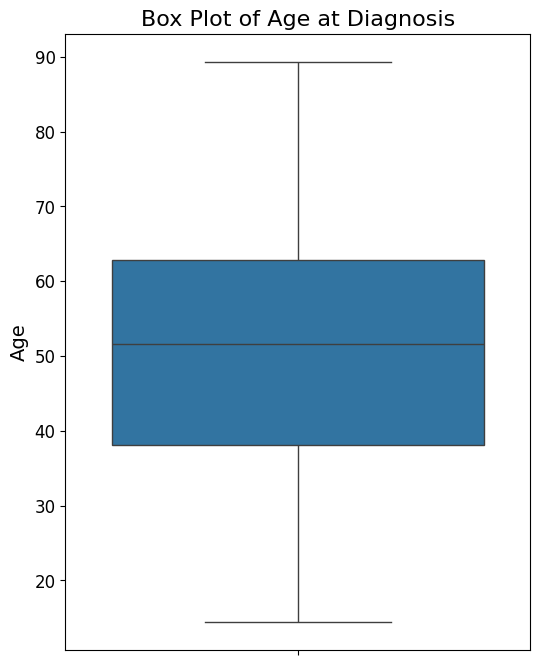

In [70]:
# Box plot for Age_at_diagnosis
plt.figure(figsize=(6, 8))
sns.boxplot(y=glioma_df['Age_at_diagnosis'])
plt.title('Box Plot of Age at Diagnosis')
plt.ylabel('Age')
plt.show()

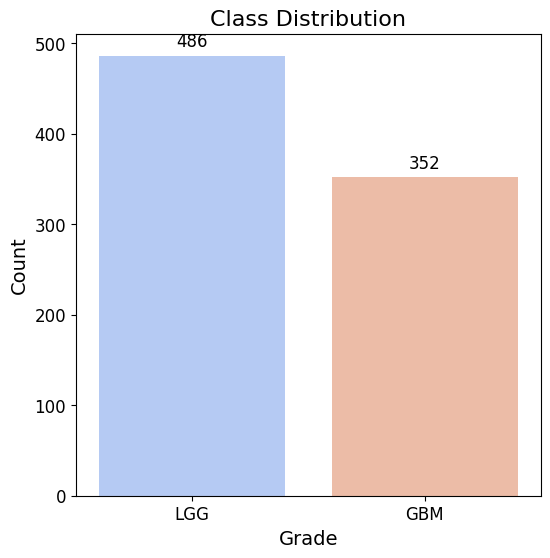

In [71]:
# Bar chart for Grade
plt.figure(figsize=(6, 6))
ax =sns.countplot(x='Grade', data=glioma_df, palette='coolwarm')
plt.title('Class Distribution')
plt.xlabel('Grade')
plt.ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center',
                va = 'center',
                xytext = (0, 10),
                textcoords = 'offset points')
plt.show()

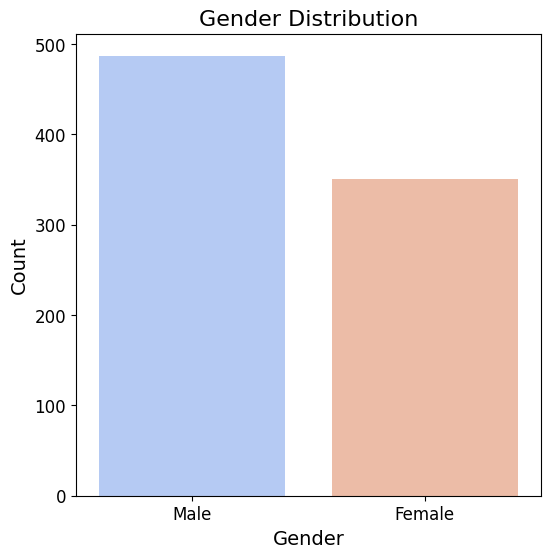

In [72]:
# Bar chart for Gender
plt.figure(figsize=(6, 6))
sns.countplot(x='Gender', data=glioma_df, palette='coolwarm')
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center',
                va = 'center',
                xytext = (0, 10),
                textcoords = 'offset points')
plt.show()

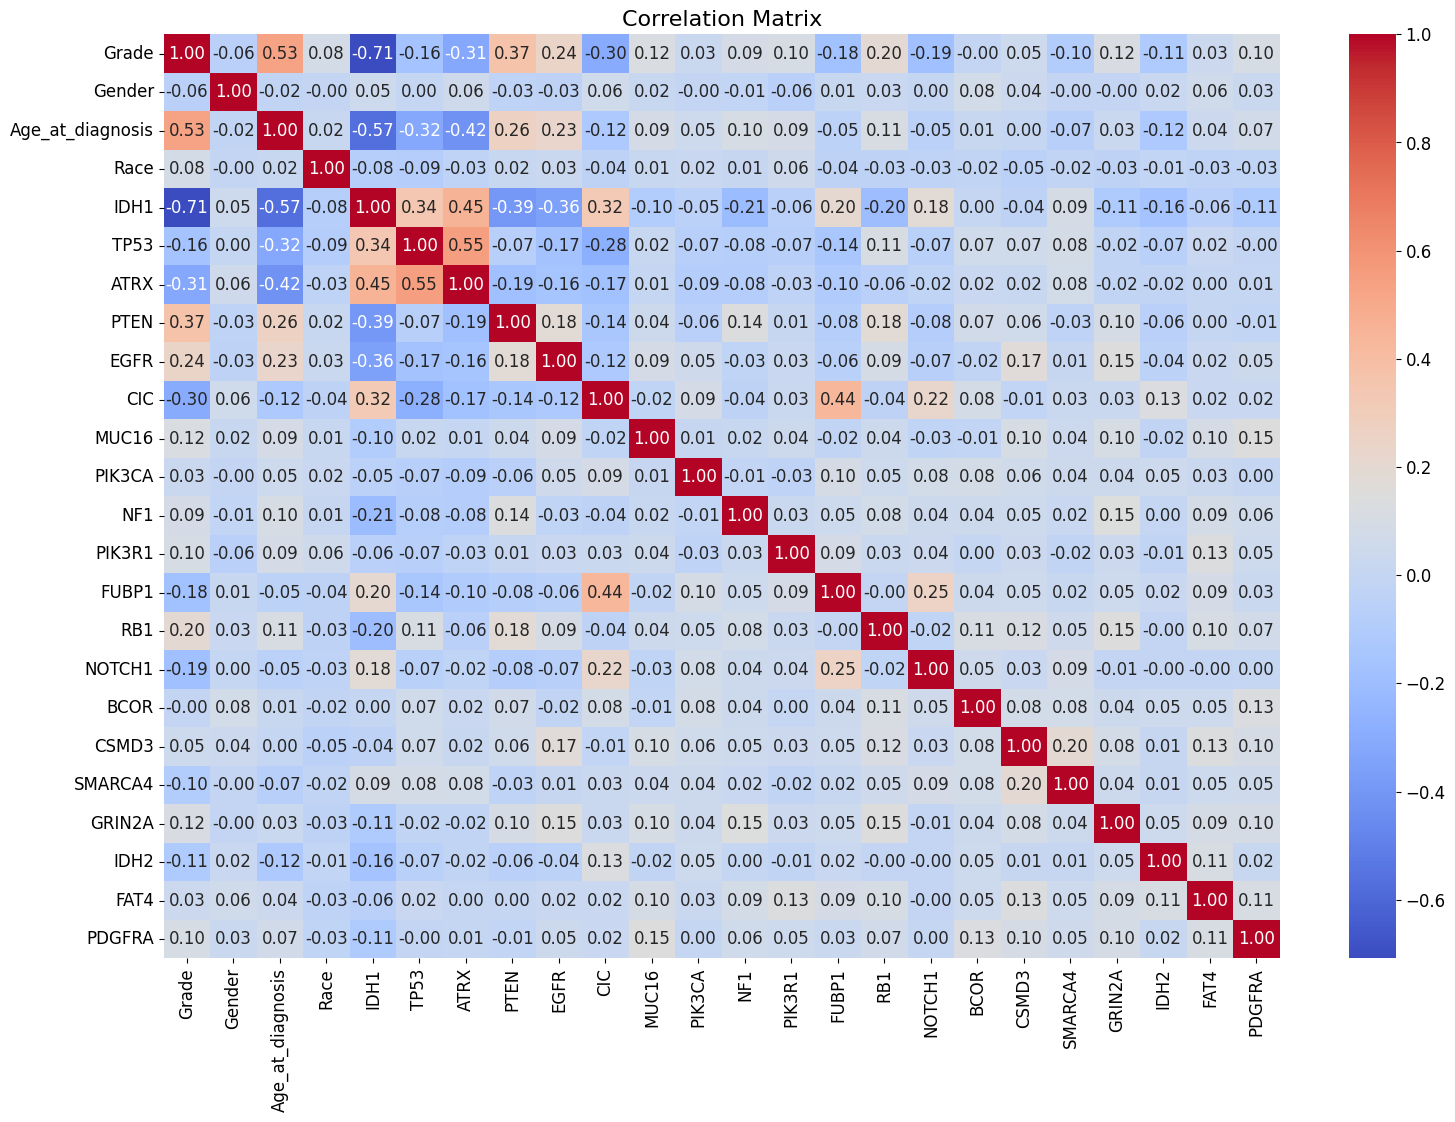

In [73]:
# Correlation matrix
correlation_matrix = Glioma_dfCopy.corr()

# Visualize the correlation matrix
plt.figure(figsize=(18, 12))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title('Correlation Matrix')
plt.show()

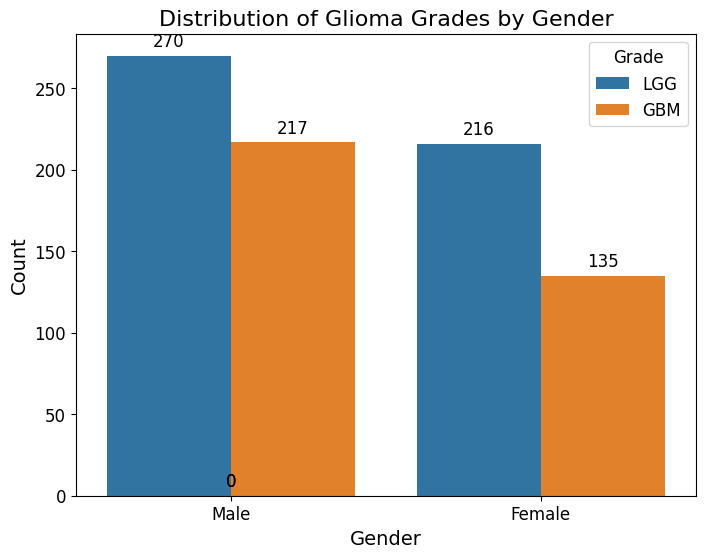

In [74]:
# Create a count plot
plt.figure(figsize=(8, 6))
ax = sns.countplot(x='Gender', hue='Grade', data=glioma_df)
plt.title('Distribution of Glioma Grades by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.legend(title='Grade')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center',
                va = 'center',
                xytext = (0, 10),
                textcoords = 'offset points')
plt.show()

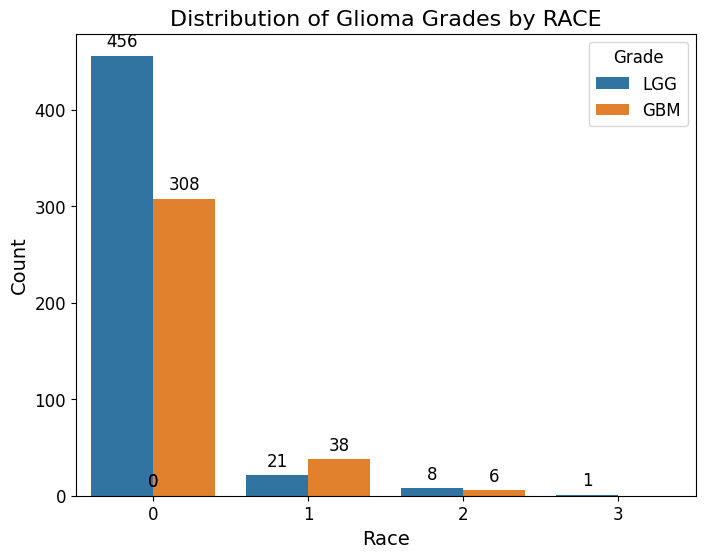

In [75]:
# Create a count plot
plt.figure(figsize=(8, 6))
ax = sns.countplot(x='Race', hue='Grade', data=glioma_df)
plt.title('Distribution of Glioma Grades by RACE')
plt.xlabel('Race')
plt.ylabel('Count')
plt.legend(title='Grade')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center',
                va = 'center',
                xytext = (0, 10),
                textcoords = 'offset points')
plt.show()

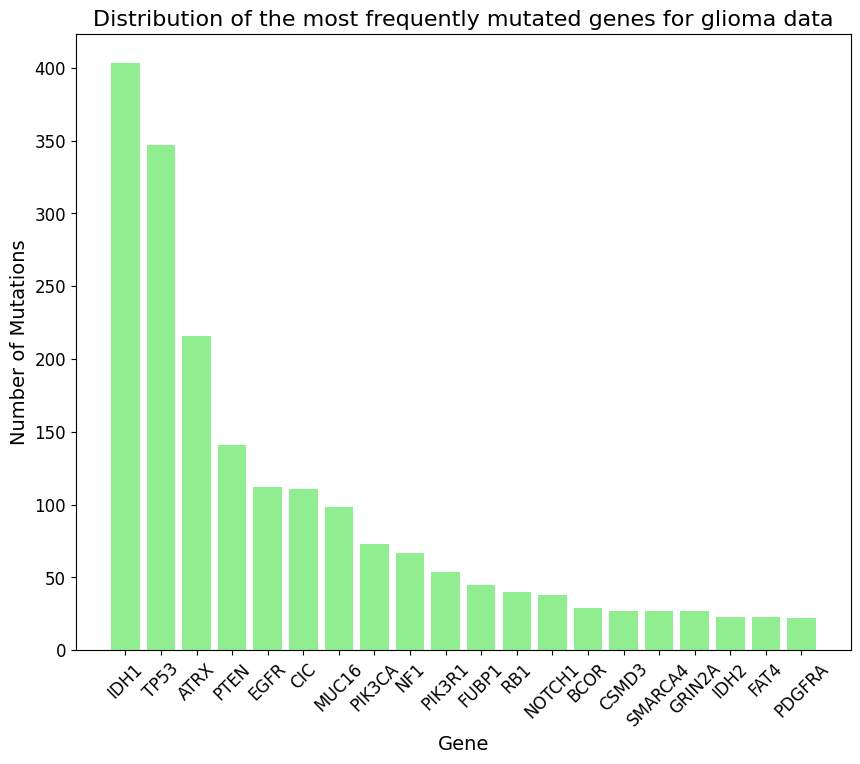

In [76]:

data =glioma_df.copy()
# Drop non-gene columns
data = data.drop(columns=['Grade', 'Age_at_diagnosis', 'Race', 'Gender'])

# Calculate mutation counts
mutation_counts = data.sum(axis=0)  # Sums up each column

# Sort mutation counts
sorted_mutation_counts = mutation_counts.sort_values(ascending=False)

# Select the top 20 most mutated genes
top_mutated_genes = sorted_mutation_counts.head(20)
plt.rcParams.update({'font.size': 12,  # Adjusts the default font size
                     'axes.labelsize': 14,  # Font size of the x and y labels
                     'xtick.labelsize': 12,  # Font size of the tick labels on x-axis
                     'ytick.labelsize': 12,  # Font size of the tick labels on y-axis
                     'axes.titlesize': 16})  # Font size of the title
# Plot the data using a vertical bar graph
plt.figure(figsize=(10, 8))
plt.bar(top_mutated_genes.index, top_mutated_genes.values, color='lightgreen')
plt.ylabel('Number of Mutations')
plt.xlabel('Gene')
plt.title('Distribution of the most frequently mutated genes for glioma data')
plt.xticks(rotation=45)  # Rotate gene names for better readability
plt.show()



---



---



---

## **Modelling**



In [77]:
def train_test(df, smote=0, fix=0):
    x = df.drop(columns=['Grade'])
    y = df['Grade']

    # Check if SMOTE is to be applied
    if smote != 0:
        # Initialize SMOTE object
        oversample = SMOTE()
        x, y = oversample.fit_resample(x, y)

        # Print the class distribution after SMOTE
        class_counts = y.value_counts()
        print("Class counts after applying SMOTE on 'Grade' column:")
        print(class_counts)

        # Optionally create a DataFrame showing the resampled data if 'fix' is not zero
        if fix != 0:
            res_df = pd.concat([x, y], axis=1)

    # Split the data into training and testing sets with 20% data as test set
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=seed)

    return x_train, x_test, y_train, y_test


In [78]:
def knn_model_(x_train, x_test, y_train, y_test):
    # Initialize the KNN classifier with 10 neighbors
    knn_model = KNeighborsClassifier(n_neighbors=10)
    knn_model.fit(x_train, y_train)
    predictions = knn_model.predict(x_test)

    # Evaluate the model's performance using a defined evaluate_performance function
    results['KNN Model'] = evaluate_performance("KNN Model", y_test, predictions)


In [79]:
def rf_model_(x_train, x_test, y_train, y_test):
    # Initialize the Random Forest classifier with 21 trees
    rf_model = RandomForestClassifier(n_estimators=21, random_state=seed)
    rf_model.fit(x_train, y_train)
    predictions = rf_model.predict(x_test)
    # Evaluate the model's performance using a defined evaluate_performance function
    results['RF Model'] = evaluate_performance("RF Model", y_test, predictions)


In [80]:
def svm_model_(x_train, x_test, y_train, y_test):
    # Initialize the SVM classifier with a linear kernel and regularization parameter C set to 1.0
    svm_model = SVC(kernel='linear', C=1.0, random_state=seed)
    svm_model.fit(x_train, y_train)
    predictions = svm_model.predict(x_test)

    # Evaluate the model's performance using a defined evaluate_performance function
    results['SVM Model'] = evaluate_performance("SVM Model", y_test, predictions)


In [81]:
def dt_model_(x_train, x_test, y_train, y_test):
    dt_model = DecisionTreeClassifier(random_state=seed)
    dt_model.fit(x_train, y_train)
    predictions = dt_model.predict(x_test)
    # Evaluate the model's performance using a defined evaluate_performance function
    results['DT Model'] = evaluate_performance("DT Model", y_test, predictions)


In [82]:
def nb_model_(x_train, x_test, y_train, y_test):
    nb_model = GaussianNB()
    nb_model.fit(x_train, y_train)
    predictions = nb_model.predict(x_test)
    results['NB Model'] = evaluate_performance("NB Model", y_test, predictions)


In [83]:

def nn_model_(x_train, x_test, y_train, y_test):
    nn_model = MLPClassifier(hidden_layer_sizes=(12, 7), activation='relu', random_state=seed)
    nn_model.fit(x_train, y_train)
    predictions = nn_model.predict(x_test)
    results['NN Model'] = evaluate_performance("NN Model", y_test, predictions)


In [84]:
def keras_model_(x_train, x_test, y_train, y_test):
    model_keras = Sequential()
    model_keras.add(Dense(units=30, activation='relu', input_shape=(x_train.shape[1],)))
    model_keras.add(Dense(units=15, activation='relu'))
    model_keras.add(Dense(units=1, activation='sigmoid'))
    model_keras.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

    model_keras.fit(x_train, y_train, epochs=10, batch_size=32, validation_split=0.2)
    predictions_classes = model_keras.predict(x_test)
    predictions = np.where(predictions_classes > 0.5, 1, 0)
    results['keras Model'] = evaluate_performance("keras Model", y_test, predictions)



In [85]:
def xgb_model_(x_train, x_test, y_train, y_test):
    xgb_model = xgb.XGBClassifier(objective='binary:logistic', n_estimators=4, learning_rate=0.2)
    xgb_model.fit(x_train, y_train)

    # Make predictions
    predictions = xgb_model.predict(x_test)
    results['XGB Model'] = evaluate_performance("XGB Model", y_test, predictions)



In [86]:
def ensemble_Votingmodel_(x_train, x_test, y_train, y_test, estimator):
    warnings.filterwarnings("ignore")
    ensemble = VotingClassifier(estimators=estimator, voting='hard')
    ensemble.fit(x_train, y_train)
    predictions = ensemble.predict(x_test)
    results['Voting Model'] = evaluate_performance("Voting Model", y_test, predictions)



In [87]:
def ensemble_Stackingmodel_(x_train, x_test, y_train, y_test, base_model, meta_model ):
    warnings.filterwarnings("ignore")
    ensemble = StackingClassifier(estimators=base_model, final_estimator=meta_model)
    ensemble.fit(x_train, y_train)
    predictions = ensemble.predict(x_test)
    results['Stacking Model'] = evaluate_performance("Stacking Model", y_test, predictions)



In [88]:
def evaluate_performance(model_name, y_test, predictions):
    res = {}
    res['Accuracy'] = ["{:.4f}".format(accuracy_score(y_test, predictions))]
    res['Precision'] = ["{:.4f}".format(precision_score(y_test, predictions, average='macro'))]
    res['Recall'] = ["{:.4f}".format(recall_score(y_test, predictions, average='macro'))]
    res['F1-Score'] = ["{:.4f}".format(f1_score(y_test, predictions, average='macro'))]
    res['roc_auc'] = ["{:.4f}".format(roc_auc_score(y_test, predictions, average='macro'))]
    res['MAE:'] = ["{:.4f}".format(mean_absolute_error(y_test, predictions))]

    # print(confusion_matrix(y_test, predictions))
    return res

In [89]:
nn_model = MLPClassifier(hidden_layer_sizes=(12, 7), activation='relu', random_state=seed)
rf_model = RandomForestClassifier(n_estimators=21, random_state=seed)
dt_model = DecisionTreeClassifier(random_state=seed)
svm_model = SVC(kernel='linear', C=1.0, random_state=seed)
nb_model = GaussianNB()
xgb_model = xgb.XGBClassifier(objective='binary:logistic', n_estimators=4, learning_rate=0.2)

estimators=[('neural', nn_model), ('rf', rf_model), ('SVM', svm_model)]
base_models = [('xgb', xgb_model), ('SVM', svm_model)]
meta_model = nn_model


In [90]:
def model(x_train, x_test, y_train, y_test):
    warnings.filterwarnings("ignore")
    knn_model_(x_train, x_test, y_train, y_test)
    rf_model_(x_train, x_test, y_train, y_test)
    svm_model_(x_train, x_test, y_train, y_test)
    dt_model_(x_train, x_test, y_train, y_test)
    nb_model_(x_train, x_test, y_train, y_test)
    nn_model_(x_train, x_test, y_train, y_test)
    keras_model_(x_train, x_test, y_train, y_test)
    xgb_model_(x_train, x_test, y_train, y_test)
    ensemble_Votingmodel_(x_train, x_test, y_train, y_test, estimators)
    ensemble_Stackingmodel_(x_train, x_test, y_train, y_test, base_models, meta_model)
# print(results)


In [91]:
from sklearn.inspection import permutation_importance

def perform_permutation_importance(estimator, x_train, y_train, n_features):
    estimator.fit(x_train, y_train)
    result = permutation_importance(estimator, x_train, y_train, n_repeats=10, random_state=seed)
    importances = result.importances_mean
    top_indices = importances.argsort()[-n_features:][::-1]
    selected_features = x_train.columns[top_indices]

    return selected_features

In [92]:
df = read_main()
results={}
result={}
res_df={}

Class counts for the 'Grade' column:
Grade
0    486
1    352
Name: count, dtype: int64


In [93]:
res_df['org']=df
x_train, x_test, y_train, y_test = train_test(df)
model(x_train, x_test, y_train, y_test)

result["org"] =pd.DataFrame(results).transpose()


[[80 21]
 [ 9 58]]
[[84 17]
 [10 57]]
[[83 18]
 [ 3 64]]
[[83 18]
 [15 52]]
[[74 27]
 [ 1 66]]
[[82 19]
 [ 5 62]]
Epoch 1/10
17/17 [==============================] - 1s 21ms/step - loss: 5.3993 - accuracy: 0.4216 - val_loss: 2.4316 - val_accuracy: 0.4403
Epoch 2/10
17/17 [==============================] - 0s 5ms/step - loss: 1.3549 - accuracy: 0.4291 - val_loss: 0.6595 - val_accuracy: 0.7164
Epoch 3/10
17/17 [==============================] - 0s 6ms/step - loss: 0.6986 - accuracy: 0.6007 - val_loss: 0.7067 - val_accuracy: 0.5597
Epoch 4/10
17/17 [==============================] - 0s 6ms/step - loss: 0.6675 - accuracy: 0.6549 - val_loss: 0.6478 - val_accuracy: 0.6791
Epoch 5/10
17/17 [==============================] - 0s 5ms/step - loss: 0.6524 - accuracy: 0.7034 - val_loss: 0.6446 - val_accuracy: 0.7687
Epoch 6/10
17/17 [==============================] - 0s 5ms/step - loss: 0.6444 - accuracy: 0.7631 - val_loss: 0.6401 - val_accuracy: 0.7985
Epoch 7/10
17/17 [===========================

In [94]:
seed = 741152

x_train, x_test, y_train, y_test = train_test(df, 1,1)
model(x_train, x_test, y_train, y_test)

result["smote"] = pd.DataFrame(results).transpose()


Class counts after applying SMOTE on 'Grade' column:
Grade
0    486
1    486
Name: count, dtype: int64
[[77 17]
 [17 84]]
[[78 16]
 [ 8 93]]
[[78 16]
 [ 3 98]]
[[75 19]
 [16 85]]
[[69 25]
 [ 2 99]]
[[80 14]
 [ 3 98]]
Epoch 1/10
20/20 [==============================] - 1s 18ms/step - loss: 0.7098 - accuracy: 0.5395 - val_loss: 0.6655 - val_accuracy: 0.6218
Epoch 2/10
20/20 [==============================] - 0s 4ms/step - loss: 0.6660 - accuracy: 0.5346 - val_loss: 0.6498 - val_accuracy: 0.6731
Epoch 3/10
20/20 [==============================] - 0s 4ms/step - loss: 0.6509 - accuracy: 0.6441 - val_loss: 0.6269 - val_accuracy: 0.6218
Epoch 4/10
20/20 [==============================] - 0s 4ms/step - loss: 0.6338 - accuracy: 0.6989 - val_loss: 0.6150 - val_accuracy: 0.7051
Epoch 5/10
20/20 [==============================] - 0s 4ms/step - loss: 0.6138 - accuracy: 0.6957 - val_loss: 0.6081 - val_accuracy: 0.8205
Epoch 6/10
20/20 [==============================] - 0s 4ms/step - loss: 0.5994 - a

In [95]:
seed = 1152
selected_features = perform_permutation_importance(nb_model, x_train, y_train, n_features=8)
print("Selected Features:", selected_features)

df_selected = df[selected_features]

df_selected['Grade'] = df['Grade']

x_train, x_test, y_train, y_test = train_test(df_selected)
model(x_train, x_test, y_train, y_test)

result["Sel_Fea"] = pd.DataFrame(results).transpose()

Selected Features: Index(['IDH1', 'CIC', 'Age_at_diagnosis', 'PTEN', 'ATRX', 'EGFR', 'IDH2',
       'NOTCH1'],
      dtype='object')
[[79 22]
 [10 57]]
[[84 17]
 [14 53]]
[[83 18]
 [ 3 64]]
[[84 17]
 [14 53]]
[[73 28]
 [ 3 64]]
[[83 18]
 [ 4 63]]
Epoch 1/10
17/17 [==============================] - 1s 15ms/step - loss: 1.0634 - accuracy: 0.4757 - val_loss: 0.7436 - val_accuracy: 0.5597
Epoch 2/10
17/17 [==============================] - 0s 4ms/step - loss: 0.7139 - accuracy: 0.6063 - val_loss: 0.6614 - val_accuracy: 0.7239
Epoch 3/10
17/17 [==============================] - 0s 5ms/step - loss: 0.6708 - accuracy: 0.5821 - val_loss: 0.6570 - val_accuracy: 0.7239
Epoch 4/10
17/17 [==============================] - 0s 4ms/step - loss: 0.6587 - accuracy: 0.7481 - val_loss: 0.6499 - val_accuracy: 0.6045
Epoch 5/10
17/17 [==============================] - 0s 5ms/step - loss: 0.6480 - accuracy: 0.7183 - val_loss: 0.6351 - val_accuracy: 0.8731
Epoch 6/10
17/17 [==============================] - 

In [96]:
x_train, x_test, y_train, y_test = train_test(df_selected,1)
model(x_train, x_test, y_train, y_test)

result["Sel_Fea_Smote"] = pd.DataFrame(results).transpose()

Class counts after applying SMOTE on 'Grade' column:
Grade
0    486
1    486
Name: count, dtype: int64
[[78 22]
 [12 83]]
[[79 21]
 [12 83]]
[[83 17]
 [ 6 89]]
[[82 18]
 [16 79]]
[[83 17]
 [ 6 89]]
[[83 17]
 [ 6 89]]
Epoch 1/10
20/20 [==============================] - 1s 12ms/step - loss: 3.9450 - accuracy: 0.4895 - val_loss: 2.0442 - val_accuracy: 0.5577
Epoch 2/10
20/20 [==============================] - 0s 4ms/step - loss: 1.2891 - accuracy: 0.4863 - val_loss: 0.7674 - val_accuracy: 0.4423
Epoch 3/10
20/20 [==============================] - 0s 4ms/step - loss: 0.7355 - accuracy: 0.5040 - val_loss: 0.6612 - val_accuracy: 0.5577
Epoch 4/10
20/20 [==============================] - 0s 3ms/step - loss: 0.6961 - accuracy: 0.4976 - val_loss: 0.6506 - val_accuracy: 0.5577
Epoch 5/10
20/20 [==============================] - 0s 3ms/step - loss: 0.6825 - accuracy: 0.5282 - val_loss: 0.6786 - val_accuracy: 0.6410
Epoch 6/10
20/20 [==============================] - 0s 4ms/step - loss: 0.6707 - a

In [97]:
print("*"*30+"\nOrginal data processesd: \n"+"*"*30)
print(result["org"])
print("*"*30+"\nBalanced data processesd: \n"+"*"*30)
print(result["smote"])
print("*"*30+"\nWith Selected Features and unbalanced data: \n"+"*"*30)
print(result["Sel_Fea"])
print("*"*30+"\nWith Selected Features and balanced data: \n"+"*"*30)
print(result["Sel_Fea_Smote"])

******************************
Orginal data processesd: 
******************************
                Accuracy Precision    Recall  F1-Score   roc_auc      MAE:
KNN Model       [0.8214]  [0.8165]  [0.8289]  [0.8183]  [0.8289]  [0.1786]
RF Model        [0.8393]  [0.8319]  [0.8412]  [0.8350]  [0.8412]  [0.1607]
SVM Model       [0.8750]  [0.8728]  [0.8885]  [0.8734]  [0.8885]  [0.1250]
DT Model        [0.8036]  [0.7949]  [0.7990]  [0.7966]  [0.7990]  [0.1964]
NB Model        [0.8333]  [0.8482]  [0.8589]  [0.8330]  [0.8589]  [0.1667]
NN Model        [0.8571]  [0.8540]  [0.8686]  [0.8551]  [0.8686]  [0.1429]
keras Model     [0.8452]  [0.8392]  [0.8512]  [0.8420]  [0.8512]  [0.1548]
XGB Model       [0.8631]  [0.8577]  [0.8711]  [0.8605]  [0.8711]  [0.1369]
Voting Model    [0.8690]  [0.8659]  [0.8810]  [0.8672]  [0.8810]  [0.1310]
Stacking Model  [0.8750]  [0.8728]  [0.8885]  [0.8734]  [0.8885]  [0.1250]
******************************
Balanced data processesd: 
*****************************

---
---
---